# Capitolo 8 — Reti e ottimizzazione
 **Arcangelo Distante e Cosimo Distante**

 Questo laboratorio verifica metodi con array analitici o dati sintetici. Non usa immagini esterne, pesi preaddestrati o download di dataset. Le attività aperte **N8.A1–N8.A3** chiedono di distinguere ciò che il calcolo dimostra dai limiti dell’esempio.

 ## Avvio e salvataggio
 In Google Colab, aprire il notebook dal repository GitHub attraverso **File → Apri notebook → GitHub**, oppure caricare questo file. Scegliere un runtime CPU: NumPy e Matplotlib sono sufficienti. Eseguire le celle dall’alto verso il basso; per ripartire, riavviare il runtime e rieseguire tutto. In locale usare Jupyter con Python 3, NumPy e Matplotlib. Nessun altro materiale deve essere caricato.

 I risultati sono salvati in `output_capitolo08` nella cartella di lavoro. Al termine scaricare la cartella degli output e salvare una copia del notebook eseguito. In Colab i file del runtime sono temporanei. Un’esecuzione locale non documenta automaticamente una prova svolta nel servizio Colab.


In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
OUTPUT = Path("output_capitolo08")
OUTPUT.mkdir(exist_ok=True)
risultati = {"capitolo": 8, "natura": "esempi analitici e sintetici", "dispositivo": "CPU"}
def mostra(a):
    return np.array2string(np.asarray(a), precision=6, separator=", ")


## N8.A1 — Derivate, forme e differenze finite
Prima seguiamo il neurone scalare del testo, poi la MLP a due unità. Il controllo usa differenze centrali in un punto in cui ReLU è differenziabile. **Domande:** perché la derivata rispetto a x vale 12 nel primo esempio? Quale asse di W1 identifica un’unità nascosta? Perché un controllo su matrici quadrate può non scoprire una trasposta errata?


In [2]:
def scalar_loss(w,b,x=2.,y=1.):
    return .5*(max(w*x+b,0)-y)**2
w,b,x=3.,-1.,2.
g_a=(max(w*x+b,0)-1)*float(w*x+b>0)
g=np.array([g_a*x,g_a,g_a*w])
print("Loss e gradienti (w, b, x):",scalar_loss(w,b),mostra(g))
print("Dopo SGD eta 0.1:",scalar_loss(w-.1*g[0],b-.1*g[1]))
def mlp_loss_grad(W1,b1,W2,b2,x,y):
    a=W1@x+b1;h=np.maximum(a,0);s=W2@h+b2
    p=np.exp(s-s.max());p/=p.sum();loss=-np.log(p[y])
    gs=p.copy();gs[y]-=1
    ga=(W2.T@gs)*(a>0)
    return loss,(np.outer(ga,x),ga,np.outer(gs,h),gs),p
params=[np.eye(2),np.zeros(2),np.array([[1.,-1.],[-1.,1.]]),np.zeros(2)]
loss,grads,p=mlp_loss_grad(*params,np.array([1.,2.]),0)
fd=[];analytic=[];eps=1e-5
for n,param in enumerate(params):
    for ix in np.ndindex(param.shape):
        plus=[z.copy() for z in params];minus=[z.copy() for z in params]
        plus[n][ix]+=eps;minus[n][ix]-=eps
        lp=mlp_loss_grad(*plus,np.array([1.,2.]),0)[0]
        lm=mlp_loss_grad(*minus,np.array([1.,2.]),0)[0]
        fd.append((lp-lm)/(2*eps));analytic.append(grads[n][ix])
errore=float(np.max(np.abs(np.array(fd)-analytic)))
print("Probabilità:",mostra(p),"CE:",loss,"massimo errore FD:",errore)
assert np.allclose(fd,analytic,atol=1e-7)
# Una verifica rettangolare espone gli assi che una matrice quadrata può nascondere.
rng=np.random.default_rng(8);xb=rng.normal(size=(2,3));W=rng.normal(size=(4,3));G=rng.normal(size=(2,4))
assert (xb@W.T).shape==(2,4) and (G.T@xb).shape==(4,3)
risultati["scalare"]={"loss":8.,"gradienti":g.tolist(),"loss_dopo_sgd":scalar_loss(w-.1*g[0],b-.1*g[1])}
risultati["mlp"]={"loss":float(loss),"probabilita":p.tolist(),"errore_massimo_fd":errore}


Loss e gradienti (w, b, x): 8.0 [ 8.,  4., 12.]
Dopo SGD eta 0.1: 2.000000000000001
Probabilità: [0.119203, 0.880797] CE: 2.1269280110429727 massimo errore FD: 8.456657596411787e-11


## N8.A2 — Aggiornamenti e scala
Confrontiamo traiettorie analitiche sulla stessa funzione quadratica. **Domande:** quali learning rate convergono? Perché Adam e SGD con lo stesso learning rate non fanno lo stesso passo iniziale? Questo confronto dimostra quale ottimizzatore generalizza meglio sulle immagini?


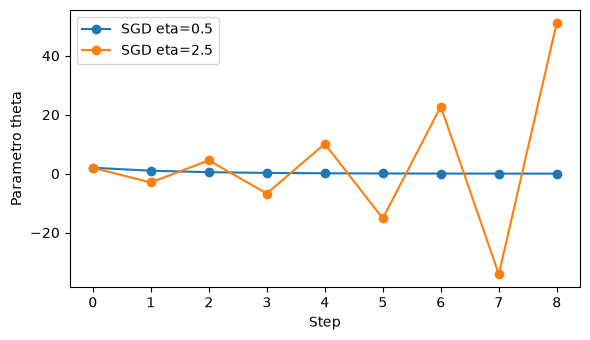

Primo parametro Adam: 1.9000000005 SGD eta 0.1: 1.8


In [3]:
def sgd(eta,steps=8):
    return 2*(1-eta)**np.arange(steps+1)
fig,ax=plt.subplots(figsize=(6,3.5))
for eta in (.5,2.5):
    t=sgd(eta);ax.plot(t,"o-",label=f"SGD eta={eta}")
ax.set(xlabel="Step",ylabel="Parametro theta");ax.legend();fig.tight_layout()
fig.savefig(OUTPUT/"sgd.png",dpi=160);plt.show()
g1=2.;m=.1*g1;v=.001*g1*g1;mhat=m/(1-.9);vhat=v/(1-.999)
theta_adam=2-.1*mhat/(np.sqrt(vhat)+1e-8)
risultati["ottimizzazione"]={"sgd_eta_05":sgd(.5).tolist(),"sgd_eta_25":sgd(2.5).tolist(),"adam_primo_passo":float(theta_adam)}
print("Primo parametro Adam:",theta_adam,"SGD eta 0.1:",1.8)


## N8.A3 — Dropout e aspettativa
Enumeriamo esattamente i due esiti di un dropout invertito; non stimiamo una media mediante training. **Domande:** quali sono media e varianza dell’uscita? Perché la loss media differisce dalla loss della media? Quale ipotesi è necessaria per usare la ricorrenza analitica della scala He in una catena di ReLU?


In [4]:
h,q=2.,.5
z=np.array([0.,h/q]);p=np.array([1-q,q]);media=float(p@z)
varianza=float(p@((z-media)**2));loss_media=float(p@(.5*(z-1)**2));loss_della_media=.5*(media-1)**2
print("Uscite:",mostra(z),"media",media,"varianza",varianza)
print("Media loss:",loss_media,"loss della media:",loss_della_media)
np.savetxt(OUTPUT/"dropout.csv",np.column_stack([z,p,.5*(z-1)**2]),delimiter=",",header="uscita,probabilita,loss",comments="")
risultati["dropout"]={"media":media,"varianza":varianza,"media_loss":loss_media,"loss_della_media":loss_della_media}
assert np.allclose([media,varianza,loss_media,loss_della_media],[2,4,2.5,.5])


Uscite: [0., 4.] media 2.0 varianza 4.0
Media loss: 2.5 loss della media: 0.5


In [5]:
with (OUTPUT / "risultati_capitolo08.json").open("w", encoding="utf-8") as f:
    json.dump(risultati, f, indent=2, ensure_ascii=False, allow_nan=False)
print("Risultati salvati in", OUTPUT)


Risultati salvati in output_capitolo08
